# Fermions on qubits

The applications in Units 3 and 4 describe electrons in a molecule and protons
and neutrons in a nucleus. They store such a system in a register the way
Notebook 00 stored bits: bit $p$ says whether a particular state of one
particle is occupied, and the operators $a_p^\dagger$ and $a_p$ add or remove
a particle there.

There is a catch. Electrons, protons and neutrons obey a sign rule that
ordinary bits do not: exchanging two of them flips the sign of the state. This
notebook shows that the operators $a_p$ from Notebook 00 break that rule, fixes
them with a string of $Z$ operators, and then measures a case where the sign
changes the answer: an energy that comes out $+1$ with the plain operators and
$-1$ with the corrected ones.

## Before you start

This notebook uses:

- the creation and annihilation operators $a^\dagger$ and $a$, and bitstrings
  in Qiskit order ([Notebook 00](00_Bits_and_Basis_States.ipynb));
- the number operator $n = a^\dagger a$, $\bar n = a a^\dagger$, the
  completeness relation $n + \bar n = I$, and the Pauli $Z$
  ([Notebook 01](01_One_Bit_Operators.ipynb));
- the subscript notation $A_k$ for an operator on bit $k$, and the hopping
  terms $a_j^\dagger a_k$ that move a 1 from bit $k$ to bit $j$
  ([Notebook 02](02_Reversible_Logic.ipynb));
- Pauli strings, Qiskit's label order (rightmost letter on qubit 0),
  `SparsePauliOp`, and the results $a = (X + iY)/2$ and
  $a_0^\dagger a_1 + a_1^\dagger a_0 = (X_0X_1 + Y_0Y_1)/2$
  ([Notebook 08](08_Pauli_Sums.ipynb));
- expectation values and the Estimator ([Notebook 09](09_Sampler_vs_Estimator.ipynb));
- the circuit that shares one 1 between two qubits, $|\Psi^+\rangle$, from
  [Notebook 10](10_Bell_States.ipynb).

Quick check:

1. What are $a|1\rangle$ and $Z|1\rangle$?
2. Write $a_0^\dagger a_1 + a_1^\dagger a_0$ as a Pauli sum.
3. What state does $H_0$ followed by CX (control 0, target 1) make from
   $|10\rangle$?

Answers: $|0\rangle$ and $-|1\rangle$; $(X_0X_1 + Y_0Y_1)/2$, or
`SparsePauliOp(["XX", "YY"], [0.5, 0.5])`; $|\Psi^+\rangle = (|01\rangle + |10\rangle)/\sqrt2$.

After this notebook you will be able to:

1. Decide, by applying set and clear operators to bitstrings, whether two of
   them give the same result in either order.
2. Write the operator that removes a particle from bit $p$ of a register, for
   particles whose state changes sign when two are exchanged, as a product of
   Pauli operators.
3. Predict the sign of a hopping term between two bits from which bits between
   them hold a 1, and check the prediction with the Estimator.

## Setup

This cell loads the libraries and decides where circuits run. By default it
uses only the simulator; the hardware exercises at the end change that.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit (Sampler jobs)
    precision=0.02,              # target standard error (Estimator jobs)
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Orbitals and occupation numbers

A molecule or nucleus has a list of single-particle states its particles can
be in. An *orbital* is one of these single-particle states. The
hydrogen-molecule notebook in Unit 3, for example, uses four orbitals.

Number the orbitals $0, 1, \dots, N-1$ and give each one a bit: 1 if a particle
occupies it, 0 if not. An *occupation-number state* is the resulting
bitstring, $|x_{N-1} \cdots x_1 x_0\rangle$ with $x_p \in \{0, 1\}$ and orbital
0 on the right, written with the bit letters of Notebook 00. In words: it
lists which orbitals are occupied. The state
$|0101\rangle$ has particles in orbitals 0 and 2. Mathematically an
occupation-number state is a bitstring, so everything from Notebooks 00 to 03
applies to it.

A *fermion* is a kind of particle that obeys two rules. Electrons, protons and
neutrons are fermions. The rules are facts about nature, found by experiment;
this notebook does not derive them.

1. No two identical fermions occupy the same orbital.
2. Exchanging two identical fermions flips the sign of the state.

Qubits already obey the first rule, for two reasons: a bit holds 0 or 1,
never 2, and $(a^\dagger)^2 = 0$ (Notebook 00, Exercise 3), so adding a second
particle to an occupied orbital gives the zero vector. The second rule is the
subject of this notebook.

**Check.** Which orbitals are occupied in $|0110\rangle$?

## Do the qubit operators follow the sign rule?

Rule 2 has a direct consequence for operators. Fill two empty orbitals $p$ and
$q$ in two different orders: first $p$ then $q$, or first $q$ then $p$. Label
the particles by the order in which they were added. In the first order,
particle 1 sits in orbital $p$ and particle 2 in orbital $q$; in the second,
particle 1 sits in $q$ and particle 2 in $p$. Both results have the same two
orbitals occupied, and they differ only in which particle is in which orbital,
which is what exchanging the two particles means. So for fermions the two
results must differ by a sign:

$$c_q^\dagger c_p^\dagger = -\,c_p^\dagger c_q^\dagger \qquad (p \ne q).$$

Here $c_p^\dagger$ is the operator that adds a fermion to orbital $p$; we look
for its matrix below. Do the qubit operators $a_p^\dagger$ already behave this
way?

### Example 1: filling two orbitals in both orders

**Problem.** Starting from $|00\rangle$, compute $a_1^\dagger a_0^\dagger|00\rangle$
and $a_0^\dagger a_1^\dagger|00\rangle$.

**Plan.** Apply one operator at a time, right to left, using
$a^\dagger|0\rangle = |1\rangle$ on the named bit and leaving the other bit
alone.

**Solution.**

**Subgoal 1: orbital 0 first.**

1. $a_0^\dagger$ sets bit 0: $a_0^\dagger|00\rangle = |01\rangle$.
2. $a_1^\dagger$ sets bit 1: $a_1^\dagger|01\rangle = |11\rangle$.

**Subgoal 2: orbital 1 first.**

3. $a_1^\dagger|00\rangle = |10\rangle$.
4. $a_0^\dagger|10\rangle = |11\rangle$.

**Check.** Both orders give $+|11\rangle$. The same holds as matrices: the
code cell below finds $a_1^\dagger a_0^\dagger = a_0^\dagger a_1^\dagger$.

**Takeaway.** Qubit operators on different qubits act on different factors of
the tensor product, so their order never matters. Fermion operators must give
a minus sign instead. The qubit operators break rule 2.

To state the fermion rule compactly, define the *anticommutator* of two
matrices,

$$\{A, B\} = AB + BA .$$

In words: multiply in both orders and add. Two operators anticommute
(Notebook 09) exactly when $\{A, B\} = 0$, which means $AB = -BA$.

The fermion operators $c_p$ (remove a particle from orbital $p$) and
$c_p^\dagger$ (add one) must satisfy the *anticommutation relations*

$$\{c_p, c_q\} = 0, \qquad \{c_p^\dagger, c_q^\dagger\} = 0, \qquad \{c_p, c_q^\dagger\} = \delta_{pq} I,$$

where $\delta_{pq}$ is 1 if $p = q$ and 0 otherwise. In words: operators on
different orbitals anticommute, and on the same orbital removing and adding in
the two orders add up to the identity.

The qubit operators pass the same-orbital tests. $\{a, a\} = 2a^2 = 0$, and
$\{a, a^\dagger\} = a a^\dagger + a^\dagger a = \bar n + n = I$ by completeness
(Notebook 01). They fail only for different orbitals, where they commute
instead. The code checks all three cases on a two-qubit register.

In [2]:
I2 = np.eye(2)
Z = np.diag([1, -1])
a = np.array([[0, 1], [0, 0]])


def on_qubit(op, k, num_qubits):
    """Matrix of a one-qubit operator on qubit k.

    Qiskit order: qubit 0 is the rightmost Kronecker factor.
    """
    factors = [op if q == k else I2 for q in reversed(range(num_qubits))]
    matrix = np.array([[1]])
    for f in factors:
        matrix = np.kron(matrix, f)
    return matrix


def anticommutator(A, B):
    return A @ B + B @ A


a0, a1 = on_qubit(a, 0, 2), on_qubit(a, 1, 2)
checks = {
    "a1^dag a0^dag == a0^dag a1^dag": np.allclose(a1.T @ a0.T, a0.T @ a1.T),
    "{a0, a0} == 0": np.allclose(anticommutator(a0, a0), 0),
    "{a0, a0^dag} == I": np.allclose(anticommutator(a0, a0.T), np.eye(4)),
    "{a0, a1} == 0": np.allclose(anticommutator(a0, a1), 0),
}
for name, holds in checks.items():
    print(f"{name:30s} : {holds}")

a1^dag a0^dag == a0^dag a1^dag : True
{a0, a0} == 0                  : True
{a0, a0^dag} == I              : True
{a0, a1} == 0                  : False


**Check.** If two operators both commute ($AB = BA$) and anticommute
($AB = -BA$), what must $AB$ be?

## The Jordan-Wigner transformation

We need operators that act like $a_p$ on orbital $p$ but pick up a sign when
moved past an operator on another orbital. One more fact about $a$ and $Z$
provides it.

### Example 2: $a$ and $Z$ anticommute

**Problem.** Show that $aZ = -Za$.

**Plan.** Compare the two products on each basis state.

**Solution.**

**Subgoal 1: on $|1\rangle$.**

1. $Z|1\rangle = -|1\rangle$, then $a(-|1\rangle) = -|0\rangle$. So
   $aZ|1\rangle = -|0\rangle$.
2. $a|1\rangle = |0\rangle$, then $Z|0\rangle = |0\rangle$. So
   $Za|1\rangle = |0\rangle$.

**Subgoal 2: on $|0\rangle$.**

3. $a|0\rangle = 0$, and $Z|0\rangle = |0\rangle$ is then sent to 0 by $a$.
   Both products give 0.

**Check.** On both basis states $aZ$ gives minus what $Za$ gives, so
$aZ = -Za$ as matrices. The reason: $Z$ reads the bit as $\pm1$, and $a$
changes the bit from 1 to 0, so reading before or after the change gives
opposite signs.

**Takeaway.** On the same qubit, $a$ and $Z$ anticommute. The same argument
gives $a^\dagger Z = -Z a^\dagger$.

Example 2 suggests attaching a $Z$ to every lower-numbered orbital. The
*Jordan-Wigner transformation* writes the fermion operators as

$$c_p = Z_0 Z_1 \cdots Z_{p-1}\, a_p, \qquad c_p^\dagger = Z_0 Z_1 \cdots Z_{p-1}\, a_p^\dagger,$$

with no $Z$ at all for $p = 0$. The product $Z_0 \cdots Z_{p-1}$ is the *Z
string* of orbital $p$. In words: to remove a particle from orbital $p$, clear
bit $p$ and multiply by $-1$ for every occupied orbital below $p$. The $Z$
operators act on other qubits than $a_p$, so the order of the factors in each
product does not matter.

### Example 3: $c_0$ and $c_1$ anticommute

**Problem.** With $c_0 = a_0$ and $c_1 = Z_0a_1$, compute $c_0c_1|11\rangle$
and $c_1c_0|11\rangle$.

**Plan.** Apply one factor at a time, right to left. $Z_0$ reads bit 0 and
multiplies by $+1$ if it is 0 and $-1$ if it is 1.

**Solution.**

**Subgoal 1: $c_0c_1|11\rangle$, orbital 1 first.**

1. $a_1$ clears bit 1: $a_1|11\rangle = |01\rangle$.
2. $Z_0$ reads bit 0, which is 1: $Z_0|01\rangle = -|01\rangle$. So
   $c_1|11\rangle = -|01\rangle$.
3. $c_0 = a_0$ clears bit 0: $c_0(-|01\rangle) = -|00\rangle$.

**Subgoal 2: $c_1c_0|11\rangle$, orbital 0 first.**

4. $c_0 = a_0$ clears bit 0: $c_0|11\rangle = |10\rangle$.
5. $a_1$ clears bit 1: $a_1|10\rangle = |00\rangle$.
6. $Z_0$ reads bit 0, which is now 0: $Z_0|00\rangle = |00\rangle$. So
   $c_1c_0|11\rangle = +|00\rangle$.

**Check.** The two orders give $-|00\rangle$ and $+|00\rangle$, so
$c_0c_1 = -c_1c_0$ on this state, as rule 2 requires. The code cell below
checks every anticommutation relation for three orbitals.

**Self-explanation prompt.** Why do the two orders differ? **Answer.** The
$Z_0$ inside $c_1$ reads bit 0. When $c_1$ acts first, bit 0 is still 1 and
$Z_0$ gives $-1$; when $c_0$ acts first, bit 0 has been cleared and $Z_0$
gives $+1$. That is Example 2 at work.

**Takeaway.** The Z string makes operators on different orbitals anticommute,
because moving $c_q$ past $c_p$ (with $p < q$) passes $a_p$ through the $Z_p$
in the string of $c_q$, which gives exactly one minus sign.

In [3]:
def jordan_wigner(p, num_orbitals):
    """Matrix of c_p = Z_0 ... Z_{p-1} a_p on num_orbitals qubits."""
    matrix = on_qubit(a, p, num_orbitals)
    for q in range(p):
        matrix = on_qubit(Z, q, num_orbitals) @ matrix
    return matrix


num_orbitals = 3
c = [jordan_wigner(p, num_orbitals) for p in range(num_orbitals)]
identity = np.eye(2**num_orbitals)
all_hold = True
for p in range(num_orbitals):
    for q in range(num_orbitals):
        all_hold &= np.allclose(anticommutator(c[p], c[q]), 0)
        expected = identity * (p == q)
        all_hold &= np.allclose(anticommutator(c[p], c[q].conj().T), expected)
print("all anticommutation relations hold for 3 orbitals:", all_hold)

all anticommutation relations hold for 3 orbitals: True


What sign does $c_p^\dagger$ produce? By the reverse-order rule for the
conjugate transpose (Notebook 04), $c_p^\dagger = a_p^\dagger\,Z_{p-1}\cdots Z_0$,
and since these factors act on different qubits they can be written in any
order. Apply them to an occupation-number state with orbital $p$ empty:
$a_p^\dagger$ sets bit $p$, and each $Z_q$ with $q < p$ multiplies by
$(-1)^{x_q}$, which is $-1$ exactly when orbital $q$ is occupied. The result
is the *sign rule*

$$c_p^\dagger\,|\ldots 0_p \ldots\rangle = (-1)^{\,x_0 + x_1 + \cdots + x_{p-1}}\,|\ldots 1_p \ldots\rangle .$$

In words: set bit $p$, and multiply by $-1$ once for each occupied orbital
below $p$. For example, $c_2^\dagger|011\rangle = +|111\rangle$ (two occupied
orbitals below 2) and $c_2^\dagger|001\rangle = -|101\rangle$ (one).

In [4]:
def ket(bitstring):
    # from_label builds the basis state named by a bitstring, bit 0 on the right
    return Statevector.from_label(bitstring).data


for start, end in [("011", "111"), ("001", "101")]:
    amplitude = ket(end) @ (c[2].conj().T @ ket(start))
    print(f"c2^dag |{start}> = {amplitude.real:+.0f} |{end}>")

c2^dag |011> = +1 |111>
c2^dag |001> = -1 |101>


A common mistake is to think the signs are bookkeeping that never changes a
measurable number, because a bit can hold only one particle anyway. That is
wrong. Qubits enforce rule 1 by themselves, because a bit cannot hold 2; rule
2 they do not enforce, and the experiment below
measures an energy that changes sign because of it. The idea is tempting
because every sign in this section multiplies a single bitstring, and a
Z-basis measurement of one bitstring cannot see a sign (Notebook 04). The sign
becomes visible when two bitstrings are in superposition.

**Check.** What is $c_1^\dagger|101\rangle$?

## Hopping with signs

The operators that matter in Units 3 and 4 move a particle from one orbital to
another. From Notebook 02 and Notebook 08, the qubit hopping term between bits
0 and 1 is $a_0^\dagger a_1 + a_1^\dagger a_0 = (X_0X_1 + Y_0Y_1)/2$. What is
the fermion version, and does the Z string change it?

### Example 4: hopping between orbitals 0 and 2

**Problem.** Write $c_0^\dagger c_1 + c_1^\dagger c_0$ and
$c_0^\dagger c_2 + c_2^\dagger c_0$ as Pauli sums.

**Plan.** Substitute the Jordan-Wigner forms, remove the $Z$ factors that meet
an $a$ or $a^\dagger$ on the same qubit, then use the result of Notebook 08.

**Solution.**

**Subgoal 1: two facts about $Z$ next to $a$ on the same qubit.**

1. $a^\dagger Z = a^\dagger$: $a^\dagger$ acts only on $|0\rangle$, where
   $Z$ gives $+1$, and both sides give 0 on $|1\rangle$.
2. $Z a = a$: $a$ produces $|0\rangle$, where $Z$ gives $+1$, and both sides
   give 0 on $|0\rangle$.

**Subgoal 2: neighbors, orbitals 0 and 1.**

3. Substitute $c_0 = a_0$ and $c_1 = Z_0a_1$:
   $c_0^\dagger c_1 = a_0^\dagger Z_0\, a_1$. By fact 1 on qubit 0, this is
   $a_0^\dagger a_1$.
4. $c_1^\dagger c_0 = Z_0 a_1^\dagger\, a_0 = a_1^\dagger\, Z_0 a_0$, moving
   $a_1^\dagger$ to the front because it acts on another qubit. By fact 2,
   this is $a_1^\dagger a_0$.
5. So $c_0^\dagger c_1 + c_1^\dagger c_0 = a_0^\dagger a_1 + a_1^\dagger a_0 = (X_0X_1 + Y_0Y_1)/2$,
   the qubit result of Notebook 08.

**Subgoal 3: orbitals 0 and 2, with orbital 1 between them.**

6. Substitute $c_2 = Z_0Z_1a_2$: $c_0^\dagger c_2 = a_0^\dagger Z_0\, Z_1 a_2$.
   By fact 1 on qubit 0, this is $Z_1\, a_0^\dagger a_2$.
7. $c_2^\dagger c_0 = Z_0Z_1 a_2^\dagger\, a_0 = Z_1 a_2^\dagger\, Z_0 a_0$.
   By fact 2, this is $Z_1\, a_2^\dagger a_0$.
8. Add, and use Notebook 08's result with qubit 2 in place of qubit 1:
   $c_0^\dagger c_2 + c_2^\dagger c_0 = Z_1\,(X_0X_2 + Y_0Y_2)/2 = (X_0Z_1X_2 + Y_0Z_1Y_2)/2$.

**Check.** The code cell below converts both matrices to Pauli sums with
`SparsePauliOp.from_operator`. In Qiskit labels, $X_0Z_1X_2$ is `"XZX"` and
$Y_0Z_1Y_2$ is `"YZY"`.

**Takeaway.** Between neighbors the Z strings cancel and fermion hopping
equals qubit hopping. Between orbitals that are not neighbors, a $Z$ remains on
every orbital in between, so a particle that hops "over" an occupied orbital
picks up a factor $-1$.

In [5]:
hop_01 = c[0].conj().T @ c[1] + c[1].conj().T @ c[0]
hop_02 = c[0].conj().T @ c[2] + c[2].conj().T @ c[0]
for name, hop in [("orbitals 0 and 1", hop_01), ("orbitals 0 and 2", hop_02)]:
    paulis = SparsePauliOp.from_operator(Operator(hop)).simplify()
    terms = " + ".join(f"{c.real:g} {p}" for p, c in paulis.to_list())
    print(f"{name}: {terms}")

orbitals 0 and 1: 0.5 IXX + 0.5 IYY
orbitals 0 and 2: 0.5 XZX + 0.5 YZY


The Jordan-Wigner transformation is one of several ways to satisfy the
anticommutation relations on qubits. The hydrogen-molecule notebook in Unit 3
compares it with two others, the parity and Bravyi-Kitaev mappings, which
place the signs differently and so give different Pauli strings with the same
energies. Unit 3 and the nuclei notebook in Unit 4 write the fermion
operators as $a_p^\dagger$ and $a_p$, the usual notation in chemistry and
nuclear physics; there they always mean the $c_p^\dagger$ and $c_p$ of this
notebook.

**Check.** For hopping between orbitals 1 and 2, which qubits carry a $Z$?

## The experiment

We share one particle between orbitals 0 and 2, with orbital 1 either empty or
occupied, and measure two energies: the qubit hopping energy
$h_\text{qubit} = (X_0X_2 + Y_0Y_2)/2$ and the fermion hopping energy
$h_\text{fermion} = (X_0Z_1X_2 + Y_0Z_1Y_2)/2$ from Example 4.

### Example 5: predicting the two energies

**Problem.** For $|\psi\rangle = (|1\,x_1\,0\rangle + |0\,x_1\,1\rangle)/\sqrt2$,
the particle shared equally between orbitals 0 and 2, predict
$\langle h_\text{qubit}\rangle$ and $\langle h_\text{fermion}\rangle$ for
$x_1 = 0$ and $x_1 = 1$.

**Plan.** Apply each operator to $|\psi\rangle$. If the result is $\pm|\psi\rangle$,
the expectation value is that sign (Notebook 10, Example 4).

**Solution.**

**Subgoal 1: the qubit hopping energy.**

1. $a_0^\dagger a_2$ moves the particle from orbital 2 to orbital 0, and
   $a_2^\dagger a_0$ moves it back; each term sends one bitstring of
   $|\psi\rangle$ to the other and the other to 0.
2. So $h_\text{qubit}|\psi\rangle$ swaps the two terms of $|\psi\rangle$.
   They have equal amplitudes, so $h_\text{qubit}|\psi\rangle = |\psi\rangle$
   and $\langle h_\text{qubit}\rangle = +1$, whatever $x_1$ is.

**Subgoal 2: the fermion hopping energy.**

3. $h_\text{fermion} = Z_1\,h_\text{qubit}$ by Example 4, step 8.
4. Both terms of $|\psi\rangle$ have the same bit 1, so $Z_1$ multiplies the
   whole state by $(-1)^{x_1}$.
5. So $\langle h_\text{fermion}\rangle = +1$ when orbital 1 is empty and $-1$
   when it is occupied.

**Check.** The code cell after the Encoding step computes both values exactly
with `Statevector`.

**Takeaway.** The two energies agree when the orbital in between is empty and
are opposite when it is occupied. That difference is the fermion sign, now in
a number the Estimator can measure.

### Encoding

Orbital 1 is set with a NOT gate when it should be occupied. The shared
particle is made as in Notebook 10: $H$ on qubit 0 and CX from qubit 0 to
qubit 2 give $(|0\,x_1\,0\rangle + |1\,x_1\,1\rangle)/\sqrt2$, and a NOT on
qubit 2 turns it into $(|1\,x_1\,0\rangle + |0\,x_1\,1\rangle)/\sqrt2$, the
pattern of $|\Psi^+\rangle$ on qubits 0 and 2.

orbital 1 empty     bitstrings with probability: {'001': 0.5, '100': 0.5}
orbital 1 occupied  bitstrings with probability: {'011': 0.5, '110': 0.5}


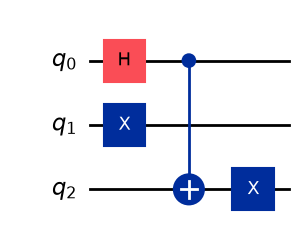

In [6]:
def shared_particle(orbital_1_occupied):
    """One particle shared equally between orbitals 0 and 2.

    Orbital 1 is occupied when orbital_1_occupied is True, empty otherwise.
    """
    qubits = QuantumRegister(3, name="q")
    circuit = QuantumCircuit(qubits, name=f"x1={int(orbital_1_occupied)}")
    if orbital_1_occupied:
        circuit.x(qubits[1])
    circuit.h(qubits[0])
    circuit.cx(qubits[0], qubits[2])
    circuit.x(qubits[2])
    return circuit


states = {
    "orbital 1 empty": shared_particle(False),
    "orbital 1 occupied": shared_particle(True),
}
for name, circuit in states.items():
    probabilities = Statevector(circuit).probabilities_dict()
    rounded = {str(b): round(float(q), 3) for b, q in probabilities.items()}
    print(f"{name:19s} bitstrings with probability: {rounded}")
states["orbital 1 occupied"].draw("mpl")

### Operator

The two energies as Pauli sums. Qiskit labels put qubit 0 on the right, so
$X_0X_2$ is `"XIX"` and $X_0Z_1X_2$ is `"XZX"`.

In [7]:
h_qubit = SparsePauliOp(["XIX", "YIY"], coeffs=[0.5, 0.5])
h_fermion = SparsePauliOp(["XZX", "YZY"], coeffs=[0.5, 0.5])
observables = [h_qubit, h_fermion]

print("exact values:")
for name, circuit in states.items():
    ideal = Statevector(circuit)
    values = [ideal.expectation_value(o).real for o in observables]
    print(f"  {name:19s} <h_qubit> = {values[0]:+.3f}   <h_fermion> = {values[1]:+.3f}")

exact values:
  orbital 1 empty     <h_qubit> = +1.000   <h_fermion> = +1.000
  orbital 1 occupied  <h_qubit> = +1.000   <h_fermion> = -1.000


### Execution

The Estimator gets the circuits without measurements. `apply_layout` rewrites
the observables for the physical qubits the transpiler chose (Notebook 09).
One PUB per state carries both observables.

In [8]:
results = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    pubs = []
    for circuit in states.values():
        isa = pass_manager.run(circuit)
        pubs.append((isa, [obs.apply_layout(isa.layout) for obs in observables]))
    job = target.estimator.run(pubs, precision=SETTINGS.precision)
    results[target.label] = target.wait(job)

### Analysis

`evs` holds the two energies and `stds` their standard errors. On the
simulator the Estimator adds random noise of size `precision` to the exact
values (Notebook 09).

In [9]:
for label, result in results.items():
    if result is None:
        continue
    print(f"Estimator on {label} (precision {SETTINGS.precision})")
    print(f"  {'state':19s} {'<h_qubit>':>17s} {'exact':>6s}"
          f"   {'<h_fermion>':>17s} {'exact':>6s}")
    for (name, circuit), pub_result in zip(states.items(), result):
        ev = np.asarray(pub_result.data.evs)
        std = np.asarray(pub_result.data.stds)
        ideal = Statevector(circuit)
        exact = [ideal.expectation_value(o).real for o in observables]
        print(f"  {name:19s} {ev[0]:+7.3f} +/- {std[0]:.3f} {exact[0]:+6.0f}"
              f"   {ev[1]:+7.3f} +/- {std[1]:.3f} {exact[1]:+6.0f}")

Estimator on aer (precision 0.02)
  state                       <h_qubit>  exact         <h_fermion>  exact
  orbital 1 empty      +1.012 +/- 0.020     +1    +1.054 +/- 0.020     +1
  orbital 1 occupied   +1.031 +/- 0.020     +1    -1.018 +/- 0.020     -1


With orbital 1 empty, both energies are $+1$. With orbital 1 occupied, the
qubit energy stays $+1$ and the fermion energy is $-1$: the particle on
orbital 1 reverses the energy of hopping past it. A calculation that used the
qubit operators for electrons would get this energy wrong in sign.

## Exercises

1. Use the sign rule to compute $c_2^\dagger|010\rangle$ and
   $c_2^\dagger|011\rangle$. Check both with `c[2]` in code.
2. Write $c_1$ for three orbitals as a Pauli sum, using $a = (X + iY)/2$ from
   Notebook 08. Give the Qiskit labels and coefficients, and check with
   `SparsePauliOp.from_operator`.
3. Show that $c_p^\dagger c_p = n_p$, the number operator of Notebook 01, with
   no Z string left. What does this say about counting the particles in a
   register?
4. With four orbitals, write $c_0^\dagger c_3 + c_3^\dagger c_0$ as a Pauli sum
   and state the rule for its sign in terms of $x_1$ and $x_2$. Check with
   `jordan_wigner(p, 4)`.
5. With orbital 1 occupied, which combination of the shared particle,
   $(|1\,1\,0\rangle + |0\,1\,1\rangle)/\sqrt2$ or
   $(|1\,1\,0\rangle - |0\,1\,1\rangle)/\sqrt2$, has the lower
   $\langle h_\text{fermion}\rangle$? Which has the lower value when orbital 1
   is empty? Make the minus combination by adding a $Z$ on qubit 0 right after
   the $H$ (Notebook 04), and check with `Statevector`.
6. True or false: a qubit can never hold two particles, so the qubit operators
   $a_p$ and $a_p^\dagger$ already describe fermions correctly. Give the
   reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. Is the difference between $\langle h_\text{qubit}\rangle$ and
   $\langle h_\text{fermion}\rangle$ with orbital 1 occupied larger than the
   printed standard errors?
8. (hardware) Compare the hardware values with the exact $\pm1$. The fermion
   energy involves a Pauli on qubit 1 and the qubit energy does not. Which of
   the two deviates more from its exact value, and how could errors on qubit 1
   explain that?

## What you can now do

1. Decide whether two set or clear operators commute or anticommute by
   applying them to bitstrings in both orders.
2. Write the fermion operator $c_p = Z_0 \cdots Z_{p-1}\,a_p$ of the
   Jordan-Wigner transformation and check its anticommutation relations.
3. Predict the sign of fermion hopping from the occupation of the orbitals in
   between, and measure it with the Estimator.

## Solutions

**Check, orbitals.** In $|0110\rangle$ bits 1 and 2 are 1, so orbitals 1 and 2
are occupied.

**Check, commute and anticommute.** From $AB = BA$ and $AB = -BA$, adding
gives $2AB = 0$, so $AB = 0$.

**Check, sign rule.** Orbital 1 is empty in $|101\rangle$ and one orbital below
it (orbital 0) is occupied, so $c_1^\dagger|101\rangle = -|111\rangle$.

**Check, hopping.** Only orbitals strictly between 1 and 2 carry a $Z$, and
there are none, so the hopping term is the qubit one,
$(X_1X_2 + Y_1Y_2)/2$, with no $Z$. (The $Z_0$ factors in $c_1$ and $c_2$
cancel because $Z_0^2 = I$.)

**Exercise 1.** **Solution.** In $|010\rangle$ orbital 2 is empty and below it
$x_0 = 0$, $x_1 = 1$: one occupied orbital, so
$c_2^\dagger|010\rangle = -|110\rangle$. In $|011\rangle$ both orbitals below 2
are occupied: two, so $c_2^\dagger|011\rangle = +|111\rangle$. **Check.**
`ket("110") @ c[2].conj().T @ ket("010")` gives $-1$, and the other gives $+1$.

**Exercise 2.** **Solution.**
1. $c_1 = Z_0a_1$.
2. Substitute $a_1 = (X_1 + iY_1)/2$: $c_1 = \tfrac12 Z_0X_1 + \tfrac{i}{2} Z_0Y_1$.
3. In Qiskit labels (qubit 2, qubit 1, qubit 0): `"IXZ"` with coefficient 0.5
   and `"IYZ"` with coefficient $0.5i$.
**Check.** `SparsePauliOp.from_operator(Operator(c[1]))` returns
`['IXZ', 'IYZ']` with coefficients `[0.5, 0.5j]`.

**Exercise 3.** **Solution.**
1. Take the conjugate transpose of $c_p = Z_0\cdots Z_{p-1}a_p$. By the
   reverse-order rule (Notebook 04) it is $a_p^\dagger Z_{p-1}\cdots Z_0$,
   because each $Z$ is its own conjugate transpose. All the factors act on
   different qubits, so they commute (Notebook 02) and
   $c_p^\dagger = Z_0\cdots Z_{p-1}a_p^\dagger$.
2. Multiply: $c_p^\dagger c_p = Z_0\cdots Z_{p-1}\,a_p^\dagger\,Z_0\cdots Z_{p-1}\,a_p$.
3. Move the second Z string next to the first; it passes only $a_p^\dagger$,
   which acts on another qubit.
4. Use $Z_q^2 = I$ for each $q$: $c_p^\dagger c_p = a_p^\dagger a_p = n_p$,
   the number operator on qubit $p$, which reads the bit $x_p$:
   $n_p|x\rangle = x_p|x\rangle$ (Notebook 01).
**Takeaway.** Counting particles needs no signs: the total number is
$\sum_p n_p = \sum_p (I - Z_p)/2$ in any register, the same expression as for
bits.

**Exercise 4.** **Solution.** Following Example 4, the $Z_0$ cancels against
$a_0^\dagger$ or $a_0$, and $Z_1Z_2$ remains:
$c_0^\dagger c_3 + c_3^\dagger c_0 = Z_1Z_2\,(X_0X_3 + Y_0Y_3)/2 = (X_0Z_1Z_2X_3 + Y_0Z_1Z_2Y_3)/2$,
with Qiskit labels `"XZZX"` and `"YZZY"`. The sign is $(-1)^{x_1 + x_2}$: $+1$
if orbitals 1 and 2 together hold an even number of particles, $-1$ if odd.
**Check.** `SparsePauliOp.from_operator` applied to the matrix built from
`jordan_wigner(0, 4)` and `jordan_wigner(3, 4)` returns these two labels with
coefficients 0.5.

**Exercise 5.** **Solution.** The two combinations are eigenvectors of
$h_\text{qubit}$ with eigenvalues $+1$ (plus) and $-1$ (minus), because the
hop swaps their two terms. Multiplying by $Z_1 = (-1)^{x_1}$:
- orbital 1 occupied: the plus combination has $\langle h_\text{fermion}\rangle = -1$,
  the lower value, and the minus combination has $+1$;
- orbital 1 empty: the minus combination has $-1$, the lower value.
**Check.** With the extra $Z$ gate, `Statevector(...).expectation_value(h_fermion)`
gives $-1$ for empty and $+1$ for occupied. The lowest-energy arrangement of the
shared particle flips with the occupation of orbital 1, which matters when
Unit 3 searches for the lowest energy of a molecule.

**Exercise 6.** False. The qubit operators enforce rule 1 (at most one particle
per orbital), but on different qubits they commute (Example 1), so they break
rule 2. The experiment shows the consequence: the hopping energy with orbital 1
occupied comes out $+1$ instead of $-1$.

**Exercise 7.** Expect the two values with orbital 1 occupied to be close to
$+1$ and $-1$ and their difference to be near 2, many standard errors apart.
Gate errors and readout errors that flip bits in either direction shrink both
values toward 0 (Notebook 09), and the Estimator's readout-error mitigation
removes much of the readout part. A difference near 2 is far larger than these
effects, so they do not hide it.

**Exercise 8.** Expect both values to be smaller in size than 1. If the
fermion energy deviates more, a plausible cause is that it also depends on
qubit 1: any error that flips qubit 1 (during the NOT, the other gates, or the
readout) flips the sign of $Z_1$ for that shot and pulls the average toward 0,
while the qubit energy ignores qubit 1. Readout-error mitigation in the
hardware Estimator reduces the readout part of this effect.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| orbital | one of the single-particle states a particle can occupy |
| occupation-number state | the bitstring $\lvert x_{N-1}\cdots x_0\rangle$ that lists which orbitals are occupied |
| fermion | a particle, such as an electron, proton or neutron, for which no two identical ones share an orbital and exchanging two flips the sign of the state |
| fermion operators $c_p^\dagger$, $c_p$ | add or remove a fermion in orbital $p$, with the signs that rule 2 requires |
| anticommutator | $\{A, B\} = AB + BA$; $A$ and $B$ anticommute when it is 0 |
| anticommutation relations | $\{c_p, c_q\} = 0$, $\{c_p^\dagger, c_q^\dagger\} = 0$, $\{c_p, c_q^\dagger\} = \delta_{pq}I$ |
| Jordan-Wigner transformation | $c_p = Z_0\cdots Z_{p-1}\,a_p$: a way to write fermion operators on qubits |
| Z string | the product $Z_0\cdots Z_{p-1}$ attached to orbital $p$ |
| sign rule | $c_p^\dagger$ multiplies by $-1$ once for each occupied orbital below $p$ |